# RVP-Example: RV64 P intrinsics
Compare scalar C and packed-SIMD intrinsics in a grayscale image search.

P **0.6 draft**; RV64 Linux, scalar C vs P intrinsics. QEMU validates execution; **it does not measure hardware speedup**. Build the local tools as described in `docs/BUILD.md`, then run from the project root. The CLI equivalent is `bash scripts/present.sh`.

In [ ]:
from pathlib import Path
import json, os, subprocess, sys
ROOT = Path(os.environ.get('RVP_EXAMPLE_ROOT', '.')).resolve()
assert (ROOT / 'VERSION.json').is_file(), 'Start in RVP-Example or set RVP_EXAMPLE_ROOT'
subprocess.run([sys.executable, str(ROOT / 'scripts/check-host.py')], check=True)
versions = json.loads((ROOT / 'VERSION.json').read_text())
print(versions['versions'])

## Eight pixels per packed SAD operation
```c
uint8x8_t av = __riscv_pld_u8x8 ((uint8_t *) (a + x));
uint8x8_t bv = __riscv_pld_u8x8 ((uint8_t *) (b + x));
sum += __riscv_pabdsumu_u8x8_u64 (av, bv);
```
The full kernel handles alignment, tails and row strides, and uses a 64-bit sum. Both kernels use the same compiler and common optimization flags; automatic vectorization and LTO are disabled.

In [ ]:
OUT = ROOT / 'build/notebook'
environment = dict(os.environ, OUT=str(OUT), OPTFLAGS='-O3')
subprocess.run(['bash', str(ROOT / 'scripts/present.sh')], env=environment, check=True)
result = json.loads((OUT / 'result.json').read_text())
print(result['tests'])
print(result['independent_image_check'])

## Image block matching
The red boxes mark the reference block and its match at **(+5, -3)**. The search map shows all 289 candidate offsets; darker means a lower SAD. The best match has **SAD = 0**.

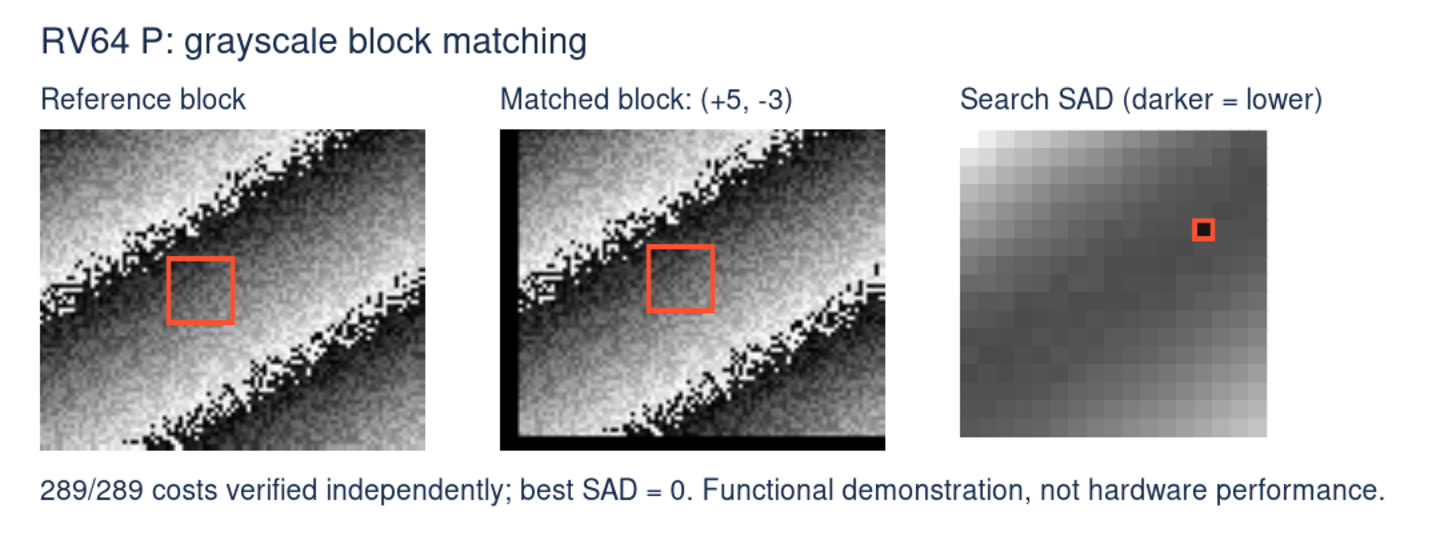

In [ ]:
subprocess.run([sys.executable, str(ROOT / 'scripts/render-demo.py'), str(OUT)], check=True)
try:
    from IPython.display import SVG, display
except ImportError:
    print('Open the visualization:', OUT / 'demo.svg')
else:
    display(SVG(filename=str(OUT / 'demo.svg')))

## Generated code and executed guest instructions
The counts below cover one 16×16 kernel call, not startup or image I/O. Aligned and unaligned cases are both included. They are **not cycles or hardware acceleration ratios**.

In [ ]:
for line in (OUT / 'sad-p.dis').read_text().splitlines():
    if 'pabdsum' in line:
        print(line)
for case in result['instruction_counts']['results']:
    print(case['kernel'], case['layout'], case['runs'][0]['guest_instructions'])
print('Kernel text bytes:', result['code_generation']['text_bytes'])
assert result['hardware_speedup'] is None
print('Hardware performance: not measured')

## Next: an agreed measurement platform
Use a P 0.6-compatible board or documented cycle model to measure cycles/pixel and throughput. Record CPU, cache and OS settings, then test an end-to-end workload.

Full three-optimization checks and negative controls: `bash scripts/acceptance.sh`. Source and measurement details: `examples/rvp-image-sad/README.md`.